# Teks — Clustering Dokumen (tanpa label)
**Kapan dipakai:** soal meminta mengelompokkan dokumen tanpa label, atau mencari kelompok
topik secara otomatis.

**Langkah:** TF-IDF → clustering K kelompok → evaluasi → kata khas tiap cluster.

**Data demo:** news4 (berita berbahasa Inggris, 4 topik). Label HANYA dipakai untuk
evaluasi (NMI/ARI), tidak dipakai saat clustering. Saat lomba biasanya tidak ada label: pakai
silhouette saja.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import AgglomerativeClustering, BisectingKMeans, KMeans, MiniBatchKMeans
from sklearn.cluster import SpectralClustering
from sklearn.decomposition import TruncatedSVD
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score, silhouette_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import Normalizer

## Konfigurasi

In [2]:
DATA_FOLDER = "../../../data_latihan/text/classification_en"   # GANTI saat lomba
DATA_CSV = f"{DATA_FOLDER}/news4_train.csv"

TEXT_COL = "text"
LABEL_COL = "label"      # hanya untuk evaluasi, hapus bila soal tidak punya label
ID_COL = "id"
N_CLUSTERS = 4
N_TOP_WORDS = 8
SEED = 42

## Baca data

In [3]:
data = pd.read_csv(DATA_CSV)
data[TEXT_COL] = data[TEXT_COL].fillna("")
print(data.shape)
print(data[LABEL_COL].value_counts())
data.head()

(2140, 3)
label
sci.med               573
comp.graphics         565
rec.autos             552
talk.politics.misc    450
Name: count, dtype: int64


,id,text,label
0,1,What kind of polygons? Shaded? Texturemapped...,comp.graphics
1,2,"Graeme> \tYes, that's known as ""Bresenhams Run...",comp.graphics
2,3,Are you using the traditional radiosity method...,comp.graphics
3,4,I need to bring on my VW Corrado for body work...,rec.autos
4,5,If she is having problems with fresh vegetable...,sci.med


## EDA: panjang dokumen

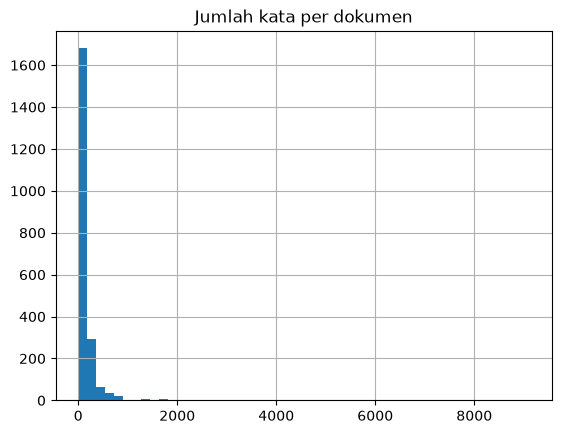

In [4]:
word_counts = data[TEXT_COL].str.split().str.len()
word_counts.hist(bins=50)
plt.title("Jumlah kata per dokumen")
plt.show()

## Model
Pilih SATU model: hapus `#` di baris yang ingin dipakai, beri `#` pada baris lain.
Versi `TruncatedSVD` = TF-IDF diringkas ke 100 dimensi dulu (LSA), sering lebih rapi.

In [5]:
vectorizer = TfidfVectorizer(stop_words="english", min_df=3, max_df=0.5, sublinear_tf=True)
X = vectorizer.fit_transform(data[TEXT_COL])

model = KMeans(n_clusters=N_CLUSTERS, n_init=10, random_state=SEED)
# model = MiniBatchKMeans(n_clusters=N_CLUSTERS, n_init=10, random_state=SEED)   # data besar
# model = BisectingKMeans(n_clusters=N_CLUSTERS, random_state=SEED)
# model = make_pipeline(TruncatedSVD(100, random_state=SEED), Normalizer(),
#                       KMeans(n_clusters=N_CLUSTERS, n_init=10, random_state=SEED))
# model = make_pipeline(TruncatedSVD(100, random_state=SEED), Normalizer(),
#                       AgglomerativeClustering(n_clusters=N_CLUSTERS))
# model = SpectralClustering(n_clusters=N_CLUSTERS, affinity="nearest_neighbors",
#                            random_state=SEED)

clusters = model.fit_predict(X)
print(pd.Series(clusters).value_counts())

2    1301
0     448
1     320
3      71
Name: count, dtype: int64


## Evaluasi
- Silhouette: −1 sampai 1, makin besar makin terpisah (tidak butuh label).
- NMI / ARI: 0 sampai 1, kecocokan dengan label asli (hanya bila label ada).

In [6]:
print("Silhouette (cosine):", round(silhouette_score(X, clusters, metric="cosine"), 4))
print("NMI:", round(normalized_mutual_info_score(data[LABEL_COL], clusters), 4))
print("ARI:", round(adjusted_rand_score(data[LABEL_COL], clusters), 4))
print(pd.crosstab(data[LABEL_COL], clusters))

Silhouette (cosine): 0.0168
NMI: 0.4494
ARI: 0.2691
col_0                 0    1    2   3
label                                
comp.graphics       424    2  139   0
rec.autos             7  317  228   0
sci.med              14    0  488  71
talk.politics.misc    3    1  446   0


## Kata khas tiap cluster (bahan memberi nama cluster)
Rata-rata bobot TF-IDF tiap kata di dalam cluster, ambil yang terbesar.

In [7]:
vocabulary = vectorizer.get_feature_names_out()
for cluster_number in range(N_CLUSTERS):
    rows = X[clusters == cluster_number]
    mean_weight = np.asarray(rows.mean(axis=0)).ravel()
    top_columns = np.argsort(mean_weight)[::-1][:N_TOP_WORDS]
    print("cluster", cluster_number, ":", " ".join(vocabulary[top_columns]))

cluster 0 : thanks graphics files file image does know program
cluster 1 : car cars engine dealer like new good just
cluster 2 : people don just like think know did time
cluster 3 : cadre dsl n3jxp chastity shameful intellect skepticism surrender


## Simpan hasil (cluster tiap dokumen)

In [8]:
result = pd.DataFrame()
result["id"] = data[ID_COL]
result["cluster"] = clusters
result.to_csv("hasil.csv", index=False)
result.head()

,id,cluster
0,1,0
1,2,0
2,3,0
3,4,2
4,5,2
